# Mão na Roda — Matriz de Confusão (config 80/10/10)

Notebook independente: carrega o modelo já treinado e salvo no Google Drive,
roda as predições no conjunto de teste e gera a matriz de confusão —
sem precisar retreinar nada.

**Ative a GPU** (Ambiente de execução → Alterar tipo de ambiente de
execução → GPU) antes de rodar, para as predições saírem mais rápido
(embora não seja estritamente necessário só para inferência).

## Passo 1 — Setup e acesso ao Drive

In [1]:
!pip install -q transformers datasets accelerate scikit-learn pandas openpyxl seaborn matplotlib

import torch
print("GPU disponível:", torch.cuda.is_available())

from google.colab import drive
drive.mount('/content/drive')
# Uma janela/pop-up do Google vai pedir autorização de acesso — isso é entre
# vocês e o Google, não passa por nós.

GPU disponível: True
Mounted at /content/drive


## Passo 2 — Encontrar o caminho certo do modelo salvo

Rodem a célula abaixo para listar as pastas dentro do seu "Meu Drive" e
localizar onde o `modelo_bertimbau_final_80_10_10` foi salvo. Ajustem o
`CAMINHO_BASE` se necessário até aparecer a pasta certa.

In [3]:
import os

CAMINHO_BASE = "/content/drive/MyDrive/Agente Mecânico/modelos/modelo_bertimbau_final_80_10_10"  # ajustem se salvaram em subpasta, ex: ".../MyDrive/mao_na_roda"

print(f"Conteúdo de {CAMINHO_BASE}:")
for item in sorted(os.listdir(CAMINHO_BASE)):
    print(" -", item)

print("\nProcurando por pastas com 'bertimbau' ou 'modelo' no nome (pode levar alguns segundos)...")
for root, dirs, files in os.walk(CAMINHO_BASE):
    for d in dirs:
        if "bertimbau" in d.lower() or "modelo" in d.lower():
            print("Encontrado:", os.path.join(root, d))

Conteúdo de /content/drive/MyDrive/Agente Mecânico/modelos/modelo_bertimbau_final_80_10_10:
 - config.json
 - model.safetensors
 - tokenizer.json
 - tokenizer_config.json
 - training_args.bin

Procurando por pastas com 'bertimbau' ou 'modelo' no nome (pode levar alguns segundos)...


In [4]:
# Depois de identificar o caminho certo na saída acima, colem ele aqui:
MODELO_PATH = "/content/drive/MyDrive/Agente Mecânico/modelos/modelo_bertimbau_final_80_10_10"  # <-- AJUSTEM ESTE CAMINHO

assert os.path.isdir(MODELO_PATH), (
    f"Pasta não encontrada em {MODELO_PATH}. Confiram o caminho na listagem acima "
    "e colem exatamente o caminho correto (copiem e colem, não digitem à mão)."
)
print("Conteúdo da pasta do modelo:")
for item in sorted(os.listdir(MODELO_PATH)):
    print(" -", item)
# Esperado: config.json, model.safetensors (ou pytorch_model.bin), tokenizer_config.json,
# vocab.txt, special_tokens_map.json, etc.

Conteúdo da pasta do modelo:
 - config.json
 - model.safetensors
 - tokenizer.json
 - tokenizer_config.json
 - training_args.bin


## Passo 3 — Carregar o modelo e o tokenizer salvos

In [5]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

NUM_LABELS = 10
LABEL_NAMES = [
    "Bateria/Sistema Elétrico", "Sistema de Freios", "Superaquecimento do Motor",
    "Suspensão/Amortecedores", "Sistema de Transmissão/Câmbio", "Vazamento de Óleo",
    "Sistema de Arrefecimento", "Pneu/Roda", "Sistema de Injeção/Combustível",
    "Sistema de Escapamento",
]

tokenizer = AutoTokenizer.from_pretrained(MODELO_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODELO_PATH, num_labels=NUM_LABELS)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()
print("Modelo e tokenizer carregados com sucesso, em:", device)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Modelo e tokenizer carregados com sucesso, em: cuda


## Passo 4 — Carregar o conjunto de teste (config 80/10/10)

Se vocês também salvaram os CSVs de split no Drive, ajustem o caminho na
célula abaixo. Caso contrário, rodem a célula de upload manual logo depois.

In [10]:
import pandas as pd

# OPÇÃO A: teste salvo no Drive (ajustem o caminho se for o caso)
TESTE_PATH_DRIVE = "/content/drive/MyDrive/Agente Mecânico/notebooks/Finetuning - 3000 relatos/3 Splits - Finetuning/Splits/split_teste_80_10_10.csv"

if os.path.isfile(TESTE_PATH_DRIVE):
    teste_df = pd.read_csv(TESTE_PATH_DRIVE)
    print("Carregado do Drive:", TESTE_PATH_DRIVE)
else:
    print("Não encontrado no Drive nesse caminho — rodem a próxima célula para upload manual.")

Carregado do Drive: /content/drive/MyDrive/Agente Mecânico/notebooks/Finetuning - 3000 relatos/3 Splits - Finetuning/Splits/split_teste_80_10_10.csv


In [ ]:
# OPÇÃO B: upload manual do split_teste_80_10_10.csv (rodem só se a célula acima não achou o arquivo)
from google.colab import files
uploaded = files.upload()
teste_df = pd.read_csv("split_teste_80_10_10.csv")
print("Linhas no teste:", len(teste_df))

## Passo 5 — Gerar predições no conjunto de teste

In [13]:
import numpy as np

MAX_LENGTH = 64
BATCH_SIZE = 32

textos = teste_df["relato"].tolist()
y_true = teste_df["falha_label"].astype(int).tolist()
y_pred = []

model.eval()
with torch.no_grad():
    for i in range(0, len(textos), BATCH_SIZE):
        batch_textos = textos[i:i+BATCH_SIZE]
        enc = tokenizer(
            batch_textos,
            truncation=True,
            max_length=MAX_LENGTH,
            padding=True,
            return_tensors="pt",
        ).to(device)
        outputs = model(**enc)
        preds = torch.argmax(outputs.logits, dim=-1)
        y_pred.extend(preds.cpu().numpy().tolist())

print("Predições geradas para", len(y_true), "exemplos do teste.")

Predições geradas para 304 exemplos do teste.


## Passo 6 — Relatório e matriz de confusão

Resultado — config 80_10_10 — conjunto de TESTE (recarregado do Drive)

                                precision    recall  f1-score   support

      Bateria/Sistema Elétrico      0.923     0.774     0.842        31
             Sistema de Freios      0.935     0.935     0.935        31
     Superaquecimento do Motor      0.679     0.633     0.655        30
       Suspensão/Amortecedores      0.900     0.871     0.885        31
 Sistema de Transmissão/Câmbio      0.906     0.935     0.921        31
             Vazamento de Óleo      0.903     0.933     0.918        30
      Sistema de Arrefecimento      0.743     0.867     0.800        30
                     Pneu/Roda      0.933     0.933     0.933        30
Sistema de Injeção/Combustível      0.897     0.867     0.881        30
        Sistema de Escapamento      0.875     0.933     0.903        30

                      accuracy                          0.868       304
                     macro avg      0.869     0.868     0.867 

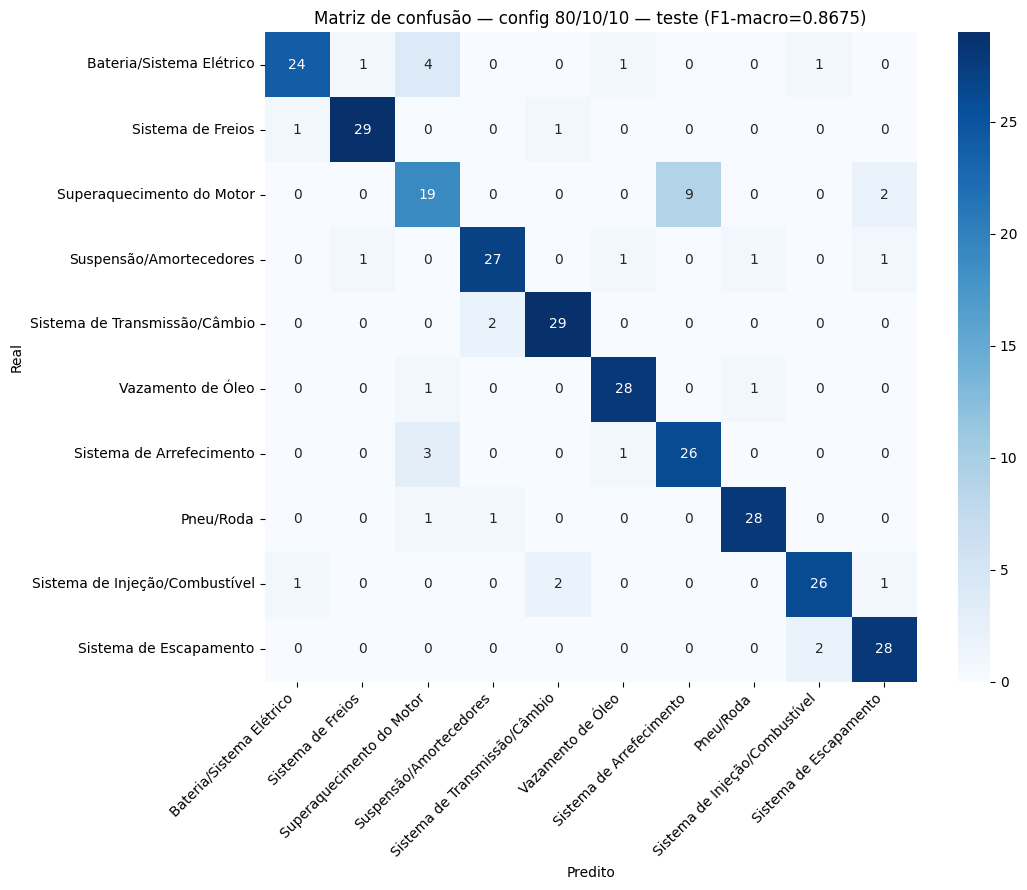


--- Checagem da hipótese Superaquecimento × Arrefecimento ---
Superaquecimento (real) confundido com Arrefecimento (predito): 9
Arrefecimento (real) confundido com Superaquecimento (predito): 3
Total de erros de Superaquecimento: 11
Total de erros de Arrefecimento: 4


In [14]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("Resultado — config 80_10_10 — conjunto de TESTE (recarregado do Drive)\n")
print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, digits=3))

f1_final = f1_score(y_true, y_pred, average="macro")
acc_final = accuracy_score(y_true, y_pred)
print(f"F1-macro: {f1_final:.4f}  |  Acurácia: {acc_final:.4f}")
print("(esses números devem bater com os do treino original: F1-macro 0,8675 / acurácia 0,8684 — "
      "se não baterem, o modelo carregado pode não ser o checkpoint certo.)")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title(f"Matriz de confusão — config 80/10/10 — teste (F1-macro={f1_final:.4f})")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("matriz_confusao_final.png", dpi=150)
plt.show()

# checagem específica: Superaquecimento (idx 2) x Arrefecimento (idx 6)
print("\n--- Checagem da hipótese Superaquecimento × Arrefecimento ---")
print("Superaquecimento (real) confundido com Arrefecimento (predito):", cm[2][6])
print("Arrefecimento (real) confundido com Superaquecimento (predito):", cm[6][2])
print("Total de erros de Superaquecimento:", cm[2].sum() - cm[2][2])
print("Total de erros de Arrefecimento:", cm[6].sum() - cm[6][6])

## Passo 7 — Salvar a imagem da matriz de volta no Drive (opcional)

In [15]:
import shutil
DESTINO_DRIVE = "/content/drive/MyDrive/Agente Mecânico/matriz_confusao_final.png"  # ajustem se quiserem outra pasta
shutil.copy("matriz_confusao_final.png", DESTINO_DRIVE)
print("Salvo em:", DESTINO_DRIVE)

Salvo em: /content/drive/MyDrive/Agente Mecânico/matriz_confusao_final.png
